## Importaciones

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score
from sklearn.metrics import accuracy_score, roc_auc_score, ConfusionMatrixDisplay

## Dataset

In [2]:
df = pd.read_feather("LICIT_depurando_sinNulos.feather")
df = df.drop_duplicates().reset_index(drop=True)

print(df.shape)
print(df["Seleccionada"].value_counts())
df.head(5)

(1887725, 50)
Seleccionada
0    1564821
1     322904
Name: count, dtype: int64


,CodigoExterno,CodigoUnidad,CantidadReclamos,MontoEstimado,NumeroOferentes,CodigoProductoONU,Cantidad,Cantidad Ofertada,Valor Total Ofertado,Seleccionada,...,Region_Región de La Araucanía,Region_Región de Los Lagos,Region_Región de Los Ríos,Region_Región de Magallanes y de la Antártica Chilena,Region_Región de Tarapacá,Region_Región de Valparaíso,Region_Región de Ñuble,Region_Región del Biobío,Region_Región del Libertador General Bernardo O'Higgins,Region_Región del Maule
0,608-60-LR23,1604,3521,645753500.0,10,42221504,60.0,60.0,486000.0,1,...,0,0,0,0,0,1,0,0,0,0
1,608-60-LR23,1604,3521,645753500.0,10,42221504,60.0,60.0,599400.0,0,...,0,0,0,0,0,1,0,0,0,0
2,608-60-LR23,1604,3521,645753500.0,10,42221504,120.0,120.0,972000.0,1,...,0,0,0,0,0,1,0,0,0,0
3,608-60-LR23,1604,3521,645753500.0,10,42221504,120.0,120.0,1198800.0,0,...,0,0,0,0,0,1,0,0,0,0
4,608-60-LR23,1604,3521,645753500.0,10,42221504,90.0,90.0,899100.0,0,...,0,0,0,0,0,1,0,0,0,0


## Variables predictoras y target


In [3]:
columnas = ["MontoEstimado", "NumeroOferentes", "Cantidad", "Cantidad Ofertada",
            "Valor Total Ofertado", "CodigoProductoONU", "DiaSemanaPublicacion"]
indicadores = df.filter(regex="^(sector_|Tipo_|Region_)").columns.tolist()

X = df[columnas + indicadores].copy()
y = df["Seleccionada"]

### Comparar precios
Una oferta por 100 unidades puede costar más que otra por 10. Para compararlas, calculamos el precio por unidad.

In [4]:
cantidad = df["Cantidad Ofertada"]
precio = df["Valor Total Ofertado"].where(df["Valor Total Ofertado"] > 0)
unitario = precio / cantidad.where(cantidad > 0)

X["precio_unitario"] = unitario
X["fraccion_cantidad"] = cantidad / df["Cantidad"].where(df["Cantidad"] > 0)
X["oferta_sobre_presupuesto"] = precio / df["MontoEstimado"].where(df["MontoEstimado"] > 0)

### Comparar ofertas de una misma compra
El archivo no incluye el ID de licitacin. Dos compras similares podrian quedar en el mismo grupo.

In [5]:
compra = ["CodigoUnidad", "AnioPublicacion", "MesPublicacion", "DiaSemanaPublicacion",
          "MontoEstimado", "NumeroOferentes"]
linea = compra + ["CodigoProductoONU", "Cantidad"]

df["unitario"] = unitario
precios = df.groupby(linea, sort=False)["unitario"]
X["precio_sobre_minimo"] = unitario / precios.transform("min")
X["precio_sobre_mediana"] = unitario / precios.transform("median")
X["puesto_relativo_precio"] = precios.rank(method="min", pct=True)
X["ofertas_con_precio"] = precios.transform("count")

In [6]:
grupos = df.groupby(compra, sort=False)
X["productos_en_proceso"] = grupos["CodigoProductoONU"].transform("nunique")
X["filas_en_proceso"] = grupos["Cantidad"].transform("size")
X["ofertas_por_producto"] = X["filas_en_proceso"] / X["productos_en_proceso"]
X["proporcion_precio_valido"] = X["ofertas_con_precio"] / precios.transform("size")
X["unidad_compradora"] = df["CodigoUnidad"]

## Train, validación y test
Usamos los meses de 2024 en orden. Entrenamos con enero agosto, elegimos el umbral con septiembre octubre y evalamos en noviembre diciembre.

In [7]:
mes = df["MesPublicacion"]
train = mes.between(1, 8)
val = mes.between(9, 10)
test = mes.between(11, 12)

X_train, y_train = X.loc[train], y.loc[train]
X_val, y_val = X.loc[val], y.loc[val]
X_test, y_test = X.loc[test], y.loc[test]

print("Train:", len(y_train), "| Validación:", len(y_val), "| Test:", len(y_test))

Train: 1373557 | Validación: 228766 | Test: 285402


## Modelo 1 · Boosting base
El modelo combina árboles de decisión. Cada árbol intenta corregir parte del error de los anteriores.

In [8]:
base = HistGradientBoostingClassifier(max_iter=200, early_stopping=False, random_state=42)
base.fit(X_train, y_train)

,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",200
,"early_stopping early_stopping: 'auto' or bool, default='auto'If 'auto', early stopping is enabled if the sample size is larger than10000 or if `X_val` and `y_val` are passed to `fit`. If True, early stoppingis enabled, otherwise early stopping is disabled... versionadded:: 0.23",False
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


## Agregar el historial para los modelos 2 y 3
Calculamos con quw frecuencia se seleccinó una oferta para un comprador o producto. En grupos pequeños damos más peso al promedio general. Para un grupo nuevo usamos ese promedio.

In [9]:
claves = pd.DataFrame({"unidad": df["CodigoUnidad"], "producto": df["CodigoProductoONU"],
                      "precio": unitario.round()})

def historial(pasado, destino):
    datos = claves.loc[pasado].assign(seleccion=y.loc[pasado])
    promedio = datos["seleccion"].mean()
    resultado = pd.DataFrame(index=destino)
    grupos = [["unidad"], ["producto"], ["unidad", "producto"],
              ["producto", "precio"], ["unidad", "producto", "precio"]]
    for columnas in grupos:
        conteo = datos.groupby(columnas)["seleccion"].agg(["sum", "count"])
        tasa = (conteo["sum"] + 20 * promedio) / (conteo["count"] + 20)
        nombre = "hist_" + "_".join(columnas)
        resultado[nombre] = claves.loc[destino].join(tasa.rename(nombre), on=columnas)[nombre]
    return resultado.fillna(promedio)

In [10]:
bloque = mes.loc[train] % 4
partes = []
for i in range(4):
    referencia = bloque[bloque != i].index
    destino = bloque[bloque == i].index
    partes.append(historial(referencia, destino))

X_train_hist = X_train.join(pd.concat(partes)).astype("float32")
X_val_hist = X_val.join(historial(X_train.index, X_val.index)).astype("float32")
X_test_hist = X_test.join(historial(X_train.index, X_test.index)).astype("float32")

## Modelo 2 · Boosting con historial

In [11]:
con_historial = HistGradientBoostingClassifier(max_iter=250, early_stopping=False, random_state=42)
con_historial.fit(X_train_hist, y_train)

,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",250
,"early_stopping early_stopping: 'auto' or bool, default='auto'If 'auto', early stopping is enabled if the sample size is larger than10000 or if `X_val` and `y_val` are passed to `fit`. If True, early stoppingis enabled, otherwise early stopping is disabled... versionadded:: 0.23",False
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


## Modelo 3 · Red neuronal
La red tiene dos capas ocultas, de 64 y 32 neuronas.

In [12]:
red = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),
    QuantileTransformer(n_quantiles=128, subsample=30000, random_state=42),
    MLPClassifier(hidden_layer_sizes=(64, 32), batch_size=512, early_stopping=True,
                  max_iter=45, n_iter_no_change=5, random_state=42)
)
muestra = X_train_hist.sample(n=min(350000, len(X_train_hist)), random_state=42)
red.fit(muestra, y_train.loc[muestra.index])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('quantiletransformer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](60,)","['MontoEstimado','NumeroOferentes','Cantidad',...,'hist_unidad_producto', 'hist_producto_precio','hist_unidad_producto_precio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,60
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",True
,"missing_values missing_valu

## Ensamble
Para cada oferta se toma  el puntaje de la clase 1 de cada modelo. Conservamos los pesos elegidos en la comparación anterior.

In [13]:
def puntajes(X_base, X_hist):
    p = pd.DataFrame(index=X_base.index)
    p["Base"] = base.predict_proba(X_base)[:, 1]
    p["Historial"] = con_historial.predict_proba(X_hist)[:, 1]
    p["Red"] = red.predict_proba(X_hist)[:, 1]
    p["Ensamble"] = 0.25 * p["Base"] + 0.50 * p["Historial"] + 0.25 * p["Red"]
    return p

p_val = puntajes(X_val, X_val_hist)

## Validación · Elegir el umbral
Cada modelo recibe el umbral que maximiza su F1 de validación. Asi se puede comparar los mdoelos bajo la misma regla


In [14]:
umbrales = {}
for nombre in p_val:
    precision, recall, cortes = precision_recall_curve(y_val, p_val[nombre])
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    umbrales[nombre] = cortes[np.argmax(f1)]

print(pd.Series(umbrales).round(4))

Base         0.2936
Historial    0.2912
Red          0.2729
Ensamble     0.2881
dtype: float64


## Test · Evaluar los modelos

In [15]:
p_test = puntajes(X_test, X_test_hist)
pred = p_test.ge(pd.Series(umbrales), axis="columns")
resultados = []
for nombre in pred:
    y_pred = pred[nombre]
    resultados.append([nombre, precision_score(y_test, y_pred), recall_score(y_test, y_pred),
                       f1_score(y_test, y_pred), accuracy_score(y_test, y_pred),
                       roc_auc_score(y_test, p_test[nombre])])

tabla = pd.DataFrame(resultados, columns=["Modelo", "Precisión", "Recall", "F1", "Accuracy", "ROC-AUC"])
print(tabla.round(4).to_string(index=False))

   Modelo  Precisión  Recall     F1  Accuracy  ROC-AUC
     Base     0.5073  0.4673 0.4865    0.8031   0.7823
Historial     0.5163  0.4541 0.4832    0.8061   0.7823
      Red     0.4881  0.4566 0.4718    0.7959   0.7716
 Ensamble     0.5148  0.4607 0.4862    0.8057   0.7853


## Matriz de confusión del ensamble

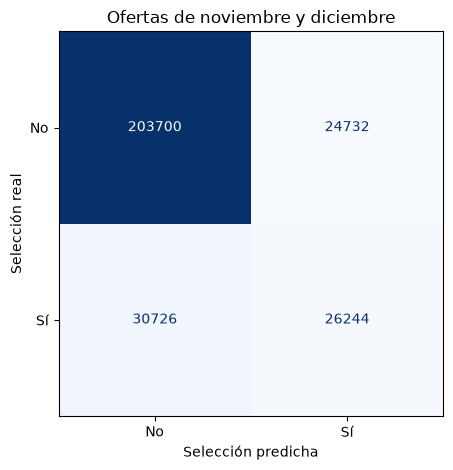

In [16]:
ConfusionMatrixDisplay.from_predictions(y_test, pred["Ensamble"], display_labels=["No", "Sí"],
                                       cmap="Blues", colorbar=False, values_format="d")
plt.xlabel("Selección predicha")
plt.ylabel("Selección real")
plt.title("Ofertas de noviembre y diciembre")
plt.tight_layout()
plt.show()

## ¿Cuántas seleccionadas pasan por alto los tres modelos?

In [17]:
ganadoras = y_test == 1
omitidas = ~pred.loc[ganadoras, ["Base", "Historial", "Red"]].any(axis=1)
print(f"Seleccionadas que los tres clasificaron como 0: {omitidas.mean():.1%}")
print(f"Seleccionadas en el conjunto de prueba: {ganadoras.mean():.1%}")

Seleccionadas que los tres clasificaron como 0: 45.9%
Seleccionadas en el conjunto de prueba: 20.0%


## ¿Por qué los modelos mejoran tan poco?

El ensamble mejoro poco: el F1 paso de 0,491 a 0,497. Los tres modelos coinciden en varios errores y dejan pasar a las mismas 47 de cada 100 ofertas ganadoras. Con estos resultados no podemos decir que los datos sean malos ni que el preprocesamiento este mal. Si hay una limitacion concreta: falta el ID de la licitacion y de su linea, asi que al agrupar podriamos estar comparando ofertas de compras distintas. Yo revisaria eso primero, por que puede influir mas que cambiar de modelo.